In [122]:
from os import rename

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

data_url = 'http://raw.githubusercontent.com/Chaile-Mendez/tp-analisis-labo/Facu/data/raw/dataset_final'
df = pd.read_csv(data_url)
df.head()


#Preguntas 2 y 4
#2: Hay un impacto en lo academico dado el uso de redes sociales?
#4: Hay un impacto en la calidad de sueño?

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
0,788,22,Male,Graduate,Canada,4.6,Instagram,No,6.7,7.0,NaN
1,703,24,Male,Undergraduate,USA,4.7,YouTube,No,7.0,6.2,NaN
2,610,24,Male,Graduate,India,2.7,Instagram,No,8.6,7.8,NaN
3,699,22,Female,Graduate,USA,6.5,YouTube,Yes,5.4,5.0,NaN
4,302,21,Male,High School,Australia,6.8,YouTube,Yes,5.7,5.0,NaN


# Como repercute el uso de redes sociales en el sueño

Se cree comunmente que el uso de pantallas durante periodos prolongados de tiempo repercute negativamente en el sueño.

Se puede observar una clara relación entre el incremento de tiempo de uso de redes sociales y la reduccion de las horas de sueño.

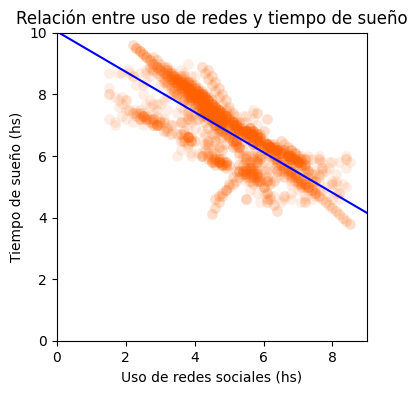

In [123]:
#Sera que el impacto se produce por la falta de sueño?

plt.figure(figsize=(4,4))

plt.scatter(
    df['Avg_Daily_Usage_Hours'],
    df['Sleep_Hours_Per_Night'],
    s=60, c='#FE6100', alpha=0.1, lw=0,)

m,b = np.polyfit(df["Avg_Daily_Usage_Hours"], df['Sleep_Hours_Per_Night'], 1)
def f(x):
  return (x * m) + b

recorrido = np.linspace(0,9,100)
plt.plot(recorrido, f(recorrido), color="blue")

plt.xlim((0,9))
plt.ylim((0,10))
plt.xlabel("Uso de redes sociales (hs)")
plt.ylabel("Tiempo de sueño (hs)")
plt.title("Relación entre uso de redes y tiempo de sueño")

plt.show()

¿Como afecta esto al rendimiento academico?

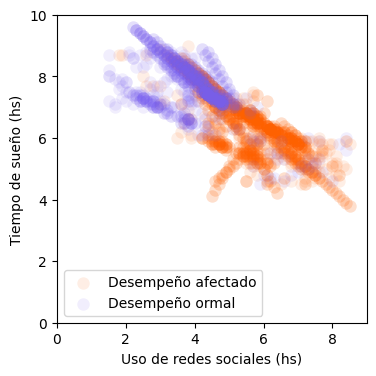

In [55]:
#Sera que el impacto se produce por la falta de sueño?

plt.figure(figsize=(4,4))

afectados = df.loc[df['Affects_Academic_Performance']=="Yes"]
no_afectados = df.loc[df['Affects_Academic_Performance']=="No"]

plt.scatter(
    afectados['Avg_Daily_Usage_Hours'],
    afectados['Sleep_Hours_Per_Night'],
    s=80, c='#FE6100', alpha=0.1, lw=0, label='Desempeño afectado')
plt.scatter(
    no_afectados['Avg_Daily_Usage_Hours'],
    no_afectados['Sleep_Hours_Per_Night'],
    s=80, c='#785EF0', alpha=0.1, lw=0, label="Desempeño ormal")

plt.xlim((0,9))
plt.ylim((0,10))
plt.xlabel("Uso de redes sociales (hs)")
plt.ylabel("Tiempo de sueño (hs)")

plt.legend()
plt.show()



(3.0, 10.0)

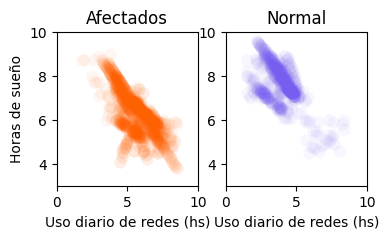

In [47]:
fig, ax = plt.subplots(1, 2, figsize=(4, 2))

ax[0].scatter(
    afectados['Avg_Daily_Usage_Hours'],
    afectados['Sleep_Hours_Per_Night'],
    s=80, c='#FE6100', alpha=0.05, lw=0, label='Mal desempeño')

ax[0].set_title("Afectados")
ax[0].set_xlabel("Uso diario de redes (hs)")
ax[0].set_xlim((0,10))
ax[0].set_ylabel("Horas de sueño")
ax[0].set_ylim((3,10))

ax[1].scatter(
    no_afectados['Avg_Daily_Usage_Hours'],
    no_afectados['Sleep_Hours_Per_Night'],
    s=80, c='#785EF0', alpha=0.05, lw=0, label="Normal")

ax[1].set_title("Normal")
ax[1].set_xlabel("Uso diario de redes (hs)")
ax[1].set_xlim((0,10))
ax[1].set_ylim((3,10))

Se puede observar que aquellos cuyo desempeño academico se vio perjudicado tienen menos horas de sueño, y mayor uso de redes sociales.

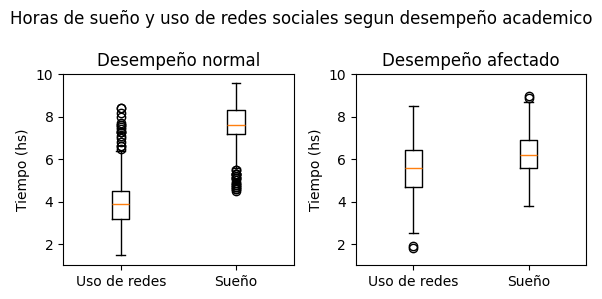

In [121]:
fig, ax = plt.subplots(1,2 ,figsize=(6, 3))

ax[0].boxplot(
    [
        no_afectados["Avg_Daily_Usage_Hours"],
        no_afectados["Sleep_Hours_Per_Night"]
    ],
    tick_labels=["Uso de redes", "Sueño"]
)
ax[1].boxplot(
    [
        afectados["Avg_Daily_Usage_Hours"],
        afectados["Sleep_Hours_Per_Night"]
    ],
    tick_labels=["Uso de redes", "Sueño"]
)

ax[0].set_title("Desempeño normal")
ax[0].set_ylabel("Tiempo (hs)")
ax[0].set_ylim((1, 10))

ax[1].set_ylabel("Tiempo (hs)")
ax[1].set_title("Desempeño afectado")
ax[1].set_ylim((1, 10))
fig.suptitle("Horas de sueño y uso de redes sociales segun desempeño academico")

plt.tight_layout()
plt.show()